In [ ]:
%pip -q install -U "transformers>=5,<6" accelerate soundfile

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 107.7 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
from zipfile import ZipFile
from google.colab import drive

drive.mount("/content/drive")
ZIP_PATH = Path("/content/drive/MyDrive/bilkis/datasets/italian Parkinson’s Voice and Speech.zip")
DATA_ROOT = Path("/content/pd_data")
RESULT_DIR = Path("/content/drive/MyDrive/pd_whisper_results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"Drive-এ ZIP পাওয়া যায়নি: {ZIP_PATH}")

if len(list(DATA_ROOT.rglob("*.wav"))) != 831:
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    with ZipFile(ZIP_PATH) as archive:
        archive.extractall(DATA_ROOT)

print("ZIP পাওয়া গেছে:", ZIP_PATH.name)
wav_count = len(list(DATA_ROOT.rglob("*.wav")))
print("Extracted WAV:", wav_count)
assert wav_count == 831, "ZIP extraction সম্পূর্ণ হয়নি। Cell 2 আবার চালাও।"
print("Results folder:", RESULT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP পাওয়া গেছে: italian Parkinson’s Voice and Speech.zip
Extracted WAV: 831
Results folder: /content/drive/MyDrive/pd_whisper_results


In [ ]:
import gc
import hashlib
import json
import re
import wave

import joblib
import numpy as np
import pandas as pd
import soundfile as sf
import torch
from IPython.display import display
from scipy.signal import resample_poly
from sklearn import __version__ as sklearn_version
from tqdm.auto import tqdm

print("GPU available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("Colab Runtime > Change runtime type থেকে GPU চালু করো।")
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__, "scikit-learn:", sklearn_version)


GPU available: True
GPU: Tesla T4
PyTorch: 2.11.0+cu130 scikit-learn: 1.6.1


In [ ]:
from pathlib import Path
import hashlib
import re
import unicodedata
import wave

import pandas as pd
from IPython.display import display

DATA_ROOT = Path("/content/pd_data")
RESULT_DIR = Path("/content/drive/MyDrive/pd_whisper_results")

if not DATA_ROOT.is_dir():
    raise FileNotFoundError("আগে ZIP extract করার cell চালাও।")
if not Path("/content/drive/MyDrive").is_dir():
    raise RuntimeError("আগে Google Drive mount করার cell চালাও।")

RESULT_DIR.mkdir(parents=True, exist_ok=True)

wav_paths = sorted(DATA_ROOT.rglob("*.wav"))
print("সব WAV পাওয়া গেছে:", len(wav_paths))

if not wav_paths:
    raise FileNotFoundError("WAV পাওয়া যায়নি। ZIP extract হয়েছে কি না দেখো।")

rows = []

for path in wav_paths:
    task = path.name[:2].upper()
    if task not in {"B1", "B2"}:
        continue

    # Original ও renamed—দুই ধরনের folder name চিনবে
    part_keys = {
        re.sub(
            r"[^a-z0-9]",
            "",
            unicodedata.normalize("NFKD", part).casefold()
        )
        for part in path.parts
    }

    if "28peoplewithparkinsonsdisease" in part_keys:
        group = "PD"
        label = 1
        session = path.parent.parent.name
    elif "22elderlyhealthycontrol" in part_keys:
        group = "Elderly HC"
        label = 0
        session = "EHC"
    else:
        continue

    # Filename থেকে birth year ও sex বের করা
    match = re.search(
        r"(\d{2})([MF])\d{6,}",
        path.stem,
        flags=re.IGNORECASE
    )
    if match is None:
        raise ValueError(f"Filename যাচাই করো: {path}")

    birth_year = match.group(1)
    sex = match.group(2).upper()
    speaker_name = path.parent.name.strip()

    raw_id = (
        f"{group}|{speaker_name.casefold()}|"
        f"{birth_year}|{sex}"
    )
    speaker_id = hashlib.sha256(
        raw_id.encode("utf-8")
    ).hexdigest()[:16]

    file_id = hashlib.sha256(
        str(path).encode("utf-8")
    ).hexdigest()[:16]

    with wave.open(str(path), "rb") as audio_file:
        sample_rate = audio_file.getframerate()
        channels = audio_file.getnchannels()
        duration_s = audio_file.getnframes() / sample_rate

    if channels != 1 or duration_s < 30:
        raise ValueError(f"Audio format/duration যাচাই করো: {path}")

    rows.append({
        "path": str(path),
        "file_id": file_id,
        "task": task,
        "group": group,
        "label": label,
        "speaker_id": speaker_id,
        "speaker_name": speaker_name,
        "birth_year": birth_year,
        "sex": sex,
        "session": session,
        "sample_rate": sample_rate,
        "duration_s": duration_s,
    })

manifest = pd.DataFrame(rows)

if manifest.empty:
    print("প্রথম WAV path:", wav_paths[0])
    raise RuntimeError("PD/Elderly HC দলের B1/B2 WAV পাওয়া যায়নি।")

if manifest.groupby("speaker_id")["label"].nunique().max() != 1:
    raise RuntimeError("একটি speaker ID-তে ভিন্ন label পাওয়া গেছে।")

manifest.to_csv(
    RESULT_DIR / "manifest_b1b2.csv",
    index=False
)

print("\nনির্বাচিত recordings:", len(manifest))
print("\nGroup, task ও sample rate অনুযায়ী সংখ্যা:")
display(
    manifest.groupby(["group", "task", "sample_rate"])
    .size()
    .rename("recordings")
)

print(
    "\nUnique speakers:",
    manifest.groupby("group")["speaker_id"].nunique().to_dict()
)

audit = (
    manifest.groupby(
        ["speaker_id", "group", "speaker_name", "birth_year", "sex"],
        as_index=False
    )
    .agg(
        recordings=("file_id", "size"),
        sessions=("session", lambda x: ", ".join(sorted(set(x))))
    )
)

print("\nএকাধিক session-এ থাকা speaker:")
display(
    audit[audit["sessions"].str.contains(",")][
        ["group", "speaker_name", "birth_year",
         "sex", "recordings", "sessions"]
    ]
)

if len(manifest) != 94:
    print("WARNING: 94টি B1/B2 recording প্রত্যাশিত।")

সব WAV পাওয়া গেছে: 831

নির্বাচিত recordings: 94

Group, task ও sample rate অনুযায়ী সংখ্যা:


group       task  sample_rate
Elderly HC  B1    16000          21
            B2    16000          21
PD          B1    16000          18
                  44100          10
            B2    16000          14
                  44100          10
Name: recordings, dtype: int64


Unique speakers: {'Elderly HC': 21, 'PD': 25}

একাধিক session-এ থাকা speaker:


,group,speaker_name,birth_year,sex,recordings,sessions
29,PD,Vito S,46,M,4,"11-16, 6-10"
38,PD,Roberto R,49,M,4,"1-5, 11-16"
42,PD,Nicola S,44,M,4,"11-16, 6-10"


In [ ]:
from transformers import AutoFeatureExtractor, WhisperModel

MODEL_ID = "openai/whisper-large-v3"
feature_extractor = AutoFeatureExtractor.from_pretrained(MODEL_ID)
model = WhisperModel.from_pretrained(
    MODEL_ID, dtype=torch.float16, low_cpu_mem_usage=True,
    use_safetensors=True,
)
encoder = model.encoder.to("cuda").eval()
del model
gc.collect()
print("Whisper encoder ready. Mel bins:", feature_extractor.feature_size)
assert feature_extractor.feature_size == 128


Loading weights:   0%|          | 0/1259 [00:00<?, ?it/s]

Whisper encoder ready. Mel bins: 128


In [ ]:
EMBED_DIR = RESULT_DIR / "embeddings_b1b2"
EMBED_DIR.mkdir(parents=True, exist_ok=True)
WINDOW_SAMPLES = 30 * 16000

def load_16k_mono(path):
    audio, sample_rate = sf.read(path, dtype="float32")
    if audio.ndim == 2:
        audio = audio.mean(axis=1)
    if sample_rate != 16000:
        from math import gcd
        factor = gcd(sample_rate, 16000)
        audio = resample_poly(audio, 16000 // factor, sample_rate // factor)
    return audio.astype(np.float32)

def thirty_second_windows(audio):
    if len(audio) < WINDOW_SAMPLES:
        raise ValueError("B1/B2 reading 30 সেকেন্ডের কম; manifest যাচাই করো।")
    starts = list(range(0, len(audio) - WINDOW_SAMPLES + 1, WINDOW_SAMPLES))
    last_start = len(audio) - WINDOW_SAMPLES
    if starts[-1] != last_start:
        starts.append(last_start)
    return [audio[start:start + WINDOW_SAMPLES] for start in starts]

for row in tqdm(manifest.itertuples(index=False), total=len(manifest)):
    out_file = EMBED_DIR / f"{row.file_id}.npy"
    if out_file.exists():
        continue

    audio = load_16k_mono(row.path)
    window_vectors = []
    for chunk in thirty_second_windows(audio):
        inputs = feature_extractor(chunk, sampling_rate=16000, return_tensors="pt")
        mel = inputs.input_features.to(device="cuda", dtype=torch.float16)
        with torch.inference_mode():
            hidden = encoder(input_features=mel).last_hidden_state
            vector = hidden.float().mean(dim=1).squeeze(0).cpu().numpy()
        window_vectors.append(vector)

    recording_vector = np.mean(np.stack(window_vectors), axis=0).astype(np.float32)
    np.save(out_file, recording_vector)

print("Saved embeddings:", len(list(EMBED_DIR.glob("*.npy"))))
print("Embedding shape:",
      np.load(EMBED_DIR / f"{manifest.iloc[0]['file_id']}.npy").shape)


  0%|          | 0/94 [00:00<?, ?it/s]

Saved embeddings: 94
Embedding shape: (1280,)


In [ ]:
speaker_rows = []
speaker_vectors = []
for speaker_id, group in manifest.groupby("speaker_id", sort=True):
    record_vectors = [
        np.load(EMBED_DIR / f"{file_id}.npy") for file_id in group["file_id"]
    ]
    speaker_vectors.append(np.mean(np.stack(record_vectors), axis=0))
    speaker_rows.append({
        "speaker_id": speaker_id,
        "label": int(group["label"].iloc[0]),
        "recordings": len(group),
    })

speakers = pd.DataFrame(speaker_rows)
X = np.stack(speaker_vectors).astype(np.float32)
y = speakers["label"].to_numpy()
np.savez_compressed(RESULT_DIR / "speaker_features_b1b2.npz",
                    X=X, y=y, speaker_id=speakers["speaker_id"].to_numpy(dtype="U16"))
print("X shape:", X.shape, "(speakers, embedding dimensions)")
print("PD speakers:", int(y.sum()), "Elderly HC speakers:", int((y == 0).sum()))


X shape: (46, 1280) (speakers, embedding dimensions)
PD speakers: 25 Elderly HC speakers: 21


Speakers: 46 | PD: 25 | Elderly HC: 21
Fold 1: test speakers=10, chosen C=1.0
Fold 2: test speakers=9, chosen C=0.1
Fold 3: test speakers=9, chosen C=0.01
Fold 4: test speakers=9, chosen C=10.0
Fold 5: test speakers=9, chosen C=0.01

Speaker-level out-of-fold AUROC: 0.9676
{
  "n_speakers": 46,
  "n_pd": 25,
  "n_healthy": 21,
  "auroc": 0.9676190476190476,
  "auprc_trapezoid": 0.9825617886178863,
  "f1_pd": 0.9583333333333334,
  "accuracy": 0.9565217391304348,
  "threshold": 0.5
}
Confusion matrix [Healthy, PD]:
[[21  0]
 [ 2 23]]
              precision    recall  f1-score   support

  Elderly HC       0.91      1.00      0.95        21
          PD       1.00      0.92      0.96        25

    accuracy                           0.96        46
   macro avg       0.96      0.96      0.96        46
weighted avg       0.96      0.96      0.96        46



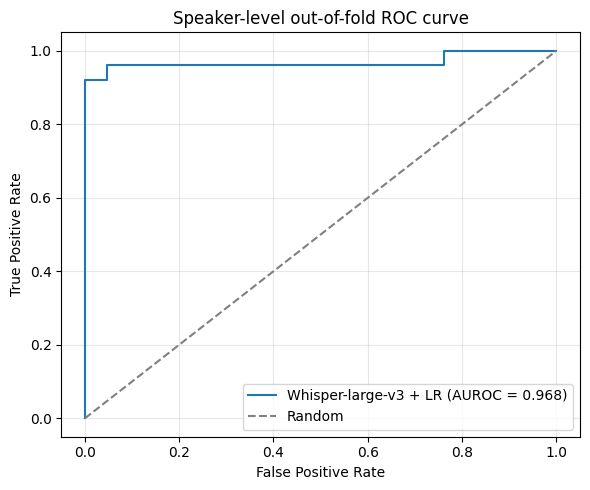

ROC, predictions ও metrics Google Drive-এ save হয়েছে: /content/drive/MyDrive/pd_whisper_results


In [ ]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, auc, classification_report, confusion_matrix,
    f1_score, precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RESULT_DIR = Path("/content/drive/MyDrive/pd_whisper_results")
feature_file = RESULT_DIR / "speaker_features_b1b2.npz"
manifest_file = RESULT_DIR / "manifest_b1b2.csv"

if not feature_file.is_file() or not manifest_file.is_file():
    raise FileNotFoundError(
        "speaker_features_b1b2.npz বা manifest_b1b2.csv পাওয়া যায়নি। "
        "আগের data তৈরির cell-গুলো চালাও।"
    )

# পুরোনো .npz-তে speaker_id object type-এ আছে। তাই X ও y পড়ি,
# তারপর একই sorted speaker order-এ manifest থেকে ID নিই।
with np.load(feature_file, allow_pickle=False) as data:
    X = data["X"].astype(np.float32)
    y = data["y"].astype(int)

manifest_check = pd.read_csv(
    manifest_file,
    usecols=["speaker_id", "label"],
    dtype={"speaker_id": str},
)
if manifest_check.groupby("speaker_id")["label"].nunique().max() != 1:
    raise ValueError("একই speaker ID-র একাধিক label আছে।")
speaker_labels = manifest_check.groupby("speaker_id", sort=True)["label"].first()
speaker_ids = speaker_labels.index.to_numpy(dtype="U16")

if X.ndim != 2 or len(X) != len(y) or len(y) != len(speaker_ids):
    raise ValueError("X, y এবং manifest-এর speaker সংখ্যা মিলছে না।")
if not np.array_equal(y, speaker_labels.to_numpy(dtype=int)):
    raise ValueError("NPZ ও manifest-এর speaker order/label মিলছে না।")
if not np.isfinite(X).all():
    raise ValueError("Embedding-এ NaN বা infinity আছে।")
if set(np.unique(y)) != {0, 1}:
    raise ValueError("Healthy=0 ও PD=1—দুই label-ই থাকতে হবে।")

print("Speakers:", len(y), "| PD:", int((y == 1).sum()),
      "| Elderly HC:", int((y == 0).sum()))

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(solver="liblinear", max_iter=5000)),
])
param_grid = {"lr__C": [0.01, 0.1, 1.0, 10.0]}
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

oof_prob = np.full(len(y), np.nan, dtype=np.float64)
fold_number = np.zeros(len(y), dtype=int)
for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y), start=1):
    search = GridSearchCV(
        pipeline, param_grid, scoring="roc_auc", cv=inner_cv
    )
    search.fit(X[train_idx], y[train_idx])
    oof_prob[test_idx] = search.predict_proba(X[test_idx])[:, 1]
    fold_number[test_idx] = fold
    print(f"Fold {fold}: test speakers={len(test_idx)}, "
          f"chosen C={search.best_params_['lr__C']}")

if not np.isfinite(oof_prob).all() or (fold_number == 0).any():
    raise RuntimeError("সব speaker-এর out-of-fold prediction তৈরি হয়নি।")

# প্রতিটি probability এমন model থেকে এসেছে যা সেই speaker-কে train-এ দেখেনি।
auroc = roc_auc_score(y, oof_prob)
oof_pred = (oof_prob >= 0.5).astype(int)
precision, recall, _ = precision_recall_curve(y, oof_prob)
metrics = {
    "n_speakers": int(len(y)),
    "n_pd": int((y == 1).sum()),
    "n_healthy": int((y == 0).sum()),
    "auroc": float(auroc),
    "auprc_trapezoid": float(auc(recall, precision)),
    "f1_pd": float(f1_score(y, oof_pred)),
    "accuracy": float(accuracy_score(y, oof_pred)),
    "threshold": 0.5,
}
print("\nSpeaker-level out-of-fold AUROC:", f"{auroc:.4f}")
print(json.dumps(metrics, indent=2))
print("Confusion matrix [Healthy, PD]:")
print(confusion_matrix(y, oof_pred))
print(classification_report(y, oof_pred, target_names=["Elderly HC", "PD"]))

fpr, tpr, _ = roc_curve(y, oof_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Whisper-large-v3 + LR (AUROC = {auroc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Speaker-level out-of-fold ROC curve")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(RESULT_DIR / "roc_curve_b1b2.png", dpi=200)
plt.show()

predictions = pd.DataFrame({
    "speaker_id": speaker_ids,
    "true_label": y,
    "fold": fold_number,
    "pd_probability": oof_prob,
    "predicted_label": oof_pred,
})
predictions.to_csv(RESULT_DIR / "oof_predictions_b1b2.csv", index=False)
with open(RESULT_DIR / "metrics_b1b2.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
print("ROC, predictions ও metrics Google Drive-এ save হয়েছে:", RESULT_DIR)


In [ ]:
final_search = GridSearchCV(pipeline, param_grid, scoring="roc_auc", cv=inner_cv)
final_search.fit(X, y)
final_model = final_search.best_estimator_
joblib.dump(final_model, RESULT_DIR / "whisper_lr_b1b2.joblib")
print("Final C:", final_search.best_params_["lr__C"])
print("Saved in:", RESULT_DIR)
print("       oof_predictions_b1b2.csv, metrics_b1b2.json, whisper_lr_b1b2.joblib")


Final C: 1.0
Saved in: /content/drive/MyDrive/pd_whisper_results
       oof_predictions_b1b2.csv, metrics_b1b2.json, whisper_lr_b1b2.joblib


In [ ]:
# NEW CELL 1 — audit and rebuild one feature vector per speaker
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd

RESULT_DIR = Path("/content/drive/MyDrive/pd_whisper_results")
manifest_file = RESULT_DIR / "manifest_b1b2.csv"
embed_dir = RESULT_DIR / "embeddings_b1b2"
if not manifest_file.is_file() or not embed_dir.is_dir():
    raise FileNotFoundError("আগে Drive mount, manifest এবং Whisper embedding-এর cell চালাও।")

manifest_strict = pd.read_csv(
    manifest_file,
    dtype={"speaker_id": str, "file_id": str, "birth_year": str},
)
needed = {"speaker_id", "file_id", "label", "group", "speaker_name",
          "birth_year", "sex", "path"}
if not needed.issubset(manifest_strict.columns):
    raise ValueError(f"Manifest-এ column কম আছে: {needed - set(manifest_strict.columns)}")
if manifest_strict[list(needed)].isna().any().any():
    raise ValueError("Manifest-এ খালি ID, label বা path আছে।")
if len(manifest_strict) != 94 or manifest_strict.speaker_id.nunique() != 46:
    raise ValueError("এই dataset-এ 94 recording ও 46 speaker প্রত্যাশিত; manifest যাচাই করো।")
if not manifest_strict.file_id.is_unique or not manifest_strict.path.is_unique:
    raise ValueError("একই recording manifest-এ একাধিকবার আছে।")
if (manifest_strict.groupby("speaker_id")["label"].nunique() != 1).any():
    raise ValueError("এক speaker-এর একাধিক label পাওয়া গেছে।")
if (manifest_strict.groupby("speaker_id")["group"].nunique() != 1).any():
    raise ValueError("এক speaker-এর একাধিক group পাওয়া গেছে।")
if not set(manifest_strict.label.unique()) == {0, 1}:
    raise ValueError("Label শুধু Healthy=0 এবং PD=1 হতে হবে।")

# নাম + জন্মসাল + sex-এর একই পরিচয় দুই group-এ থাকলে থামবে।
identity = (
    manifest_strict.speaker_name.str.strip().str.casefold() + "|" +
    manifest_strict.birth_year.str.strip() + "|" +
    manifest_strict.sex.str.strip().str.upper()
)
if (manifest_strict.assign(identity=identity)
    .groupby("identity")["group"].nunique() > 1).any():
    raise ValueError("PD ও Healthy group-এ একই speaker পরিচয় পাওয়া গেছে।")

# Audio file-এর exact duplicate অন্য speaker-এ আছে কি না যাচাই।
audio_hash_to_speaker = {}
for row in manifest_strict.itertuples(index=False):
    audio_path = Path(row.path)
    if not audio_path.is_file():
        raise FileNotFoundError(f"WAV নেই: {audio_path}। ZIP extraction cell চালাও।")
    hasher = hashlib.sha256()
    with audio_path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            hasher.update(block)
    digest = hasher.hexdigest()
    previous_speaker = audio_hash_to_speaker.setdefault(digest, row.speaker_id)
    if previous_speaker != row.speaker_id:
        raise ValueError("দুই speaker-এর WAV byte-for-byte এক! Dataset যাচাই করো।")

# Saved Whisper vectors থেকে speaker-level X নতুন করে তৈরি।
# Whisper এখানে frozen; এটি এই dataset-এ fit/tune করা হচ্ছে না।
speaker_ids, labels, vectors = [], [], []
for speaker_id, rows in manifest_strict.groupby("speaker_id", sort=True):
    recordings = []
    for file_id in rows.file_id:
        embedding_file = embed_dir / f"{file_id}.npy"
        if not embedding_file.is_file():
            raise FileNotFoundError(f"Embedding নেই: {embedding_file}")
        vector = np.load(embedding_file, allow_pickle=False)
        if vector.shape != (1280,) or not np.isfinite(vector).all():
            raise ValueError(f"Embedding shape/value ভুল: {embedding_file}")
        recordings.append(vector.astype(np.float32))
    speaker_ids.append(speaker_id)
    labels.append(int(rows.label.iloc[0]))
    vectors.append(np.stack(recordings).mean(axis=0))

speaker_ids = np.asarray(speaker_ids, dtype="U16")
X_strict = np.stack(vectors).astype(np.float32)
y_strict = np.asarray(labels, dtype=int)
if len(set(speaker_ids)) != len(speaker_ids) or not np.isfinite(X_strict).all():
    raise ValueError("Speaker ID duplicate বা X-এ NaN/Inf আছে।")

class_counts = np.bincount(y_strict, minlength=2)
if tuple(class_counts) != (21, 25):
    raise ValueError(f"প্রত্যাশিত 21 Healthy ও 25 PD speaker নেই: {class_counts}")

# Test fold-এ প্রতি class-এর অন্তত 4 speaker রাখি; সর্বোচ্চ 5 fold।
# AUROC দেখে fold সংখ্যা নির্বাচন করা হচ্ছে না।
OUTER_FOLDS = min(5, int(class_counts.min()) // 4)
INNER_FOLDS = 4
if OUTER_FOLDS < 2:
    raise ValueError("এই dataset-এ নির্ভরযোগ্য outer fold বানানোর মতো speaker নেই।")
print("Audit passed: recordings=", len(manifest_strict),
      "speakers=", len(y_strict), "Healthy/PD=", class_counts.tolist())
print("Nested CV plan:", OUTER_FOLDS, "outer folds;",
      INNER_FOLDS, "inner folds")


Audit passed: recordings= 94 speakers= 46 Healthy/PD= [21, 25]
Nested CV plan: 5 outer folds; 4 inner folds


In [ ]:
# NEW CELL 2 — strict speaker-level nested CV and one OOF prediction per speaker
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

outer = StratifiedKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=42)
oof_probability = np.full(len(y_strict), np.nan)
oof_fold = np.zeros(len(y_strict), dtype=int)
oof_chosen_c = np.full(len(y_strict), np.nan)
fold_rows = []

# Grid আগে থেকেই নির্ধারিত। Outer test-এর score দিয়ে grid বদলাবে না।
C_GRID = [0.01, 0.1, 1.0, 10.0]
for fold, (train_idx, test_idx) in enumerate(outer.split(X_strict, y_strict), 1):
    train_ids = set(speaker_ids[train_idx])
    test_ids = set(speaker_ids[test_idx])
    assert train_ids.isdisjoint(test_ids), "এক speaker train ও test—দুই জায়গায়!"
    assert np.isnan(oof_probability[test_idx]).all(), "OOF test speaker duplicate!"

    train_files = set(manifest_strict.loc[
        manifest_strict.speaker_id.isin(train_ids), "file_id"])
    test_files = set(manifest_strict.loc[
        manifest_strict.speaker_id.isin(test_ids), "file_id"])
    assert train_files.isdisjoint(test_files), "এক recording train ও test—দুই জায়গায়!"

    train_counts = np.bincount(y_strict[train_idx], minlength=2)
    test_counts = np.bincount(y_strict[test_idx], minlength=2)
    assert train_counts.min() >= INNER_FOLDS
    assert test_counts.min() >= 4

    # StandardScaler প্রতিটি inner training fold-এর ভেতরে fit হয়।
    pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("lr", LogisticRegression(solver="liblinear", max_iter=5000)),
    ])
    inner = StratifiedKFold(
        n_splits=INNER_FOLDS, shuffle=True, random_state=100 + fold
    )
    search = GridSearchCV(
        pipeline, {"lr__C": C_GRID}, cv=inner,
        scoring="roc_auc", refit=True, error_score="raise",
    )
    search.fit(X_strict[train_idx], y_strict[train_idx])
    probabilities = search.predict_proba(X_strict[test_idx])[:, 1]
    oof_probability[test_idx] = probabilities
    oof_fold[test_idx] = fold
    oof_chosen_c[test_idx] = search.best_params_["lr__C"]
    fold_auc = roc_auc_score(y_strict[test_idx], probabilities)
    fold_rows.append({
        "fold": fold, "train_speakers": len(train_idx),
        "test_speakers": len(test_idx),
        "test_healthy": int(test_counts[0]), "test_pd": int(test_counts[1]),
        "chosen_C": search.best_params_["lr__C"], "fold_auroc": fold_auc,
    })
    print(f"Fold {fold}: train={len(train_idx)}, test={len(test_idx)}, "
          f"Healthy/PD={test_counts.tolist()}, C={search.best_params_['lr__C']}, "
          f"AUROC={fold_auc:.4f}")

assert np.isfinite(oof_probability).all(), "কোনো speaker-এর OOF probability নেই।"
assert (oof_fold > 0).all(), "কোনো speaker test fold পায়নি।"
assert len(np.unique(speaker_ids)) == len(oof_probability)
fold_table = pd.DataFrame(fold_rows)


Fold 1: train=36, test=10, Healthy/PD=[5, 5], C=0.01, AUROC=0.9200
Fold 2: train=37, test=9, Healthy/PD=[4, 5], C=0.1, AUROC=1.0000
Fold 3: train=37, test=9, Healthy/PD=[4, 5], C=0.1, AUROC=1.0000
Fold 4: train=37, test=9, Healthy/PD=[4, 5], C=0.1, AUROC=1.0000
Fold 5: train=37, test=9, Healthy/PD=[4, 5], C=0.01, AUROC=1.0000


{
  "n_recordings": 94,
  "n_speakers": 46,
  "n_outer_folds": 5,
  "n_inner_folds": 4,
  "mean_fold_auroc": 0.984,
  "sd_fold_auroc": 0.03577708763999661,
  "pooled_oof_auroc": 0.9904761904761905,
  "oof_accuracy_at_0_5": 0.9565217391304348,
  "oof_f1_pd_at_0_5": 0.9583333333333334,
  "threshold": 0.5
}
Confusion matrix, rows=true, columns=predicted, order=[Healthy, PD]:
[[21  0]
 [ 2 23]]


,fold,train_speakers,test_speakers,test_healthy,test_pd,chosen_C,fold_auroc
0,1,36,10,5,5,0.01,0.92
1,2,37,9,4,5,0.10,1.00
2,3,37,9,4,5,0.10,1.00
3,4,37,9,4,5,0.10,1.00
4,5,37,9,4,5,0.01,1.00


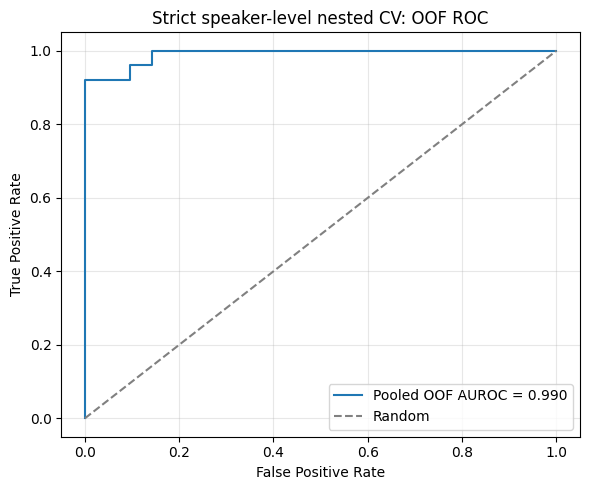

Saved strict OOF results to: /content/drive/MyDrive/pd_whisper_results


In [ ]:
# NEW CELL 3 — report ONLY held-out OOF metrics and save predictions
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, roc_auc_score, roc_curve,
)

pooled_oof_auroc = float(roc_auc_score(y_strict, oof_probability))
mean_fold_auroc = float(fold_table.fold_auroc.mean())
sd_fold_auroc = float(fold_table.fold_auroc.std(ddof=1))
oof_label = (oof_probability >= 0.5).astype(int)  # fixed, untuned threshold
summary = {
    "n_recordings": int(len(manifest_strict)),
    "n_speakers": int(len(y_strict)),
    "n_outer_folds": OUTER_FOLDS,
    "n_inner_folds": INNER_FOLDS,
    "mean_fold_auroc": mean_fold_auroc,
    "sd_fold_auroc": sd_fold_auroc,
    "pooled_oof_auroc": pooled_oof_auroc,
    "oof_accuracy_at_0_5": float(accuracy_score(y_strict, oof_label)),
    "oof_f1_pd_at_0_5": float(f1_score(y_strict, oof_label)),
    "threshold": 0.5,
}
print(json.dumps(summary, indent=2))
print("Confusion matrix, rows=true, columns=predicted, order=[Healthy, PD]:")
print(confusion_matrix(y_strict, oof_label, labels=[0, 1]))
display(fold_table)

oof_table = pd.DataFrame({
    "speaker_id": speaker_ids,
    "true_label": y_strict,
    "outer_fold": oof_fold,
    "chosen_C_from_inner_CV": oof_chosen_c,
    "oof_pd_probability": oof_probability,
    "predicted_label_at_0_5": oof_label,
})
oof_table.to_csv(RESULT_DIR / "strict_nested_oof_predictions.csv", index=False)
fold_table.to_csv(RESULT_DIR / "strict_nested_fold_metrics.csv", index=False)
with (RESULT_DIR / "strict_nested_summary.json").open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

fpr, tpr, _ = roc_curve(y_strict, oof_probability)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Pooled OOF AUROC = {pooled_oof_auroc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Strict speaker-level nested CV: OOF ROC")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / "strict_nested_oof_roc.png", dpi=200)
plt.show()
print("Saved strict OOF results to:", RESULT_DIR)


In [ ]:
# NEW CELL 4 — optional final model for future, unseen speakers
# This model uses all 46 speakers. It is NOT used to calculate the OOF AUROC.
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

final_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("lr", LogisticRegression(solver="liblinear", max_iter=5000)),
])
final_inner = StratifiedKFold(
    n_splits=INNER_FOLDS, shuffle=True, random_state=2026
)
final_search = GridSearchCV(
    final_pipeline, {"lr__C": C_GRID}, cv=final_inner,
    scoring="roc_auc", refit=True, error_score="raise",
)
final_search.fit(X_strict, y_strict)
model_path = RESULT_DIR / "whisper_lr_b1b2_strict_final.joblib"
joblib.dump(final_search.best_estimator_, model_path)
print("Final model C (full-data inner CV):", final_search.best_params_["lr__C"])
print("Final model saved:", model_path)
print("Thesis performance হিসেবে NEW CELL 3-এর held-out OOF ফল ব্যবহার করো।")


Final model C (full-data inner CV): 0.1
Final model saved: /content/drive/MyDrive/pd_whisper_results/whisper_lr_b1b2_strict_final.joblib
Thesis performance হিসেবে NEW CELL 3-এর held-out OOF ফল ব্যবহার করো।


In [ ]:
# NEW CELL 1 — audit and rebuild one feature vector per speaker
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd

RESULT_DIR = Path("/content/drive/MyDrive/pd_whisper_results")
manifest_file = RESULT_DIR / "manifest_b1b2.csv"
embed_dir = RESULT_DIR / "embeddings_b1b2"
if not manifest_file.is_file() or not embed_dir.is_dir():
    raise FileNotFoundError("আগে Drive mount, manifest এবং Whisper embedding-এর cell চালাও।")

manifest_strict = pd.read_csv(
    manifest_file,
    dtype={"speaker_id": str, "file_id": str, "birth_year": str},
)
needed = {"speaker_id", "file_id", "label", "group", "speaker_name",
          "birth_year", "sex", "path"}
if not needed.issubset(manifest_strict.columns):
    raise ValueError(f"Manifest-এ column কম আছে: {needed - set(manifest_strict.columns)}")
if manifest_strict[list(needed)].isna().any().any():
    raise ValueError("Manifest-এ খালি ID, label বা path আছে।")
if len(manifest_strict) != 94 or manifest_strict.speaker_id.nunique() != 46:
    raise ValueError("এই dataset-এ 94 recording ও 46 speaker প্রত্যাশিত; manifest যাচাই করো।")
if not manifest_strict.file_id.is_unique or not manifest_strict.path.is_unique:
    raise ValueError("একই recording manifest-এ একাধিকবার আছে।")
if (manifest_strict.groupby("speaker_id")["label"].nunique() != 1).any():
    raise ValueError("এক speaker-এর একাধিক label পাওয়া গেছে।")
if (manifest_strict.groupby("speaker_id")["group"].nunique() != 1).any():
    raise ValueError("এক speaker-এর একাধিক group পাওয়া গেছে।")
if not set(manifest_strict.label.unique()) == {0, 1}:
    raise ValueError("Label শুধু Healthy=0 এবং PD=1 হতে হবে।")

# নাম + জন্মসাল + sex-এর একই পরিচয় দুই group-এ থাকলে থামবে।
identity = (
    manifest_strict.speaker_name.str.strip().str.casefold() + "|" +
    manifest_strict.birth_year.str.strip() + "|" +
    manifest_strict.sex.str.strip().str.upper()
)
if (manifest_strict.assign(identity=identity)
    .groupby("identity")["group"].nunique() > 1).any():
    raise ValueError("PD ও Healthy group-এ একই speaker পরিচয় পাওয়া গেছে।")

# Audio file-এর exact duplicate অন্য speaker-এ আছে কি না যাচাই।
audio_hash_to_speaker = {}
for row in manifest_strict.itertuples(index=False):
    audio_path = Path(row.path)
    if not audio_path.is_file():
        raise FileNotFoundError(f"WAV নেই: {audio_path}। ZIP extraction cell চালাও।")
    hasher = hashlib.sha256()
    with audio_path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            hasher.update(block)
    digest = hasher.hexdigest()
    previous_speaker = audio_hash_to_speaker.setdefault(digest, row.speaker_id)
    if previous_speaker != row.speaker_id:
        raise ValueError("দুই speaker-এর WAV byte-for-byte এক! Dataset যাচাই করো।")

# Saved Whisper vectors থেকে speaker-level X নতুন করে তৈরি।
# Whisper এখানে frozen; এটি এই dataset-এ fit/tune করা হচ্ছে না।
speaker_ids, labels, vectors = [], [], []
for speaker_id, rows in manifest_strict.groupby("speaker_id", sort=True):
    recordings = []
    for file_id in rows.file_id:
        embedding_file = embed_dir / f"{file_id}.npy"
        if not embedding_file.is_file():
            raise FileNotFoundError(f"Embedding নেই: {embedding_file}")
        vector = np.load(embedding_file, allow_pickle=False)
        if vector.shape != (1280,) or not np.isfinite(vector).all():
            raise ValueError(f"Embedding shape/value ভুল: {embedding_file}")
        recordings.append(vector.astype(np.float32))
    speaker_ids.append(speaker_id)
    labels.append(int(rows.label.iloc[0]))
    vectors.append(np.stack(recordings).mean(axis=0))

speaker_ids = np.asarray(speaker_ids, dtype="U16")
X_strict = np.stack(vectors).astype(np.float32)
y_strict = np.asarray(labels, dtype=int)
if len(set(speaker_ids)) != len(speaker_ids) or not np.isfinite(X_strict).all():
    raise ValueError("Speaker ID duplicate বা X-এ NaN/Inf আছে।")

class_counts = np.bincount(y_strict, minlength=2)
if tuple(class_counts) != (21, 25):
    raise ValueError(f"প্রত্যাশিত 21 Healthy ও 25 PD speaker নেই: {class_counts}")

# Test fold-এ প্রতি class-এর অন্তত 4 speaker রাখি; সর্বোচ্চ 5 fold।
# AUROC দেখে fold সংখ্যা নির্বাচন করা হচ্ছে না।
OUTER_FOLDS = min(5, int(class_counts.min()) // 4)
INNER_FOLDS = 4
if OUTER_FOLDS < 2:
    raise ValueError("এই dataset-এ নির্ভরযোগ্য outer fold বানানোর মতো speaker নেই।")
print("Audit passed: recordings=", len(manifest_strict),
      "speakers=", len(y_strict), "Healthy/PD=", class_counts.tolist())
print("Nested CV plan:", OUTER_FOLDS, "outer folds;",
      INNER_FOLDS, "inner folds")


Audit passed: recordings= 94 speakers= 46 Healthy/PD= [21, 25]
Nested CV plan: 5 outer folds; 4 inner folds


In [ ]:
# NEW CELL 2 — only held-out outer-test predictions and test metrics
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, matthews_corrcoef, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def test_metrics(y_true, probability):
    """Every value here is computed from held-out test predictions only."""
    prediction = (probability >= 0.5).astype(int)  # threshold fixed before CV
    tn, fp, fn, tp = confusion_matrix(
        y_true, prediction, labels=[0, 1]
    ).ravel()
    return {
        "test_speakers": int(len(y_true)),
        "test_healthy": int((y_true == 0).sum()),
        "test_pd": int((y_true == 1).sum()),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "accuracy": float(accuracy_score(y_true, prediction)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, prediction)),
        "precision_pd": float(precision_score(
            y_true, prediction, zero_division=0
        )),
        "sensitivity_recall_pd": float(recall_score(
            y_true, prediction, zero_division=0
        )),
        "specificity_healthy": float(tn / (tn + fp)),
        "negative_predictive_value": float(
            tn / (tn + fn) if (tn + fn) else 0.0
        ),
        "f1_pd": float(f1_score(y_true, prediction, zero_division=0)),
        "f1_macro": float(f1_score(
            y_true, prediction, average="macro", zero_division=0
        )),
        "mcc": float(matthews_corrcoef(y_true, prediction)),
        "auroc": float(roc_auc_score(y_true, probability)),
        "auprc_average_precision": float(
            average_precision_score(y_true, probability)
        ),
    }

outer = StratifiedKFold(
    n_splits=OUTER_FOLDS, shuffle=True, random_state=42
)
oof_probability = np.full(len(y_strict), np.nan, dtype=float)
oof_fold = np.zeros(len(y_strict), dtype=int)
oof_count = np.zeros(len(y_strict), dtype=int)
fold_test_indices = []
fold_rows = []
C_GRID = [0.01, 0.1, 1.0, 10.0]  # fixed before viewing test scores

for fold, (train_idx, test_idx) in enumerate(
    outer.split(X_strict, y_strict), start=1
):
    train_ids = set(speaker_ids[train_idx])
    test_ids = set(speaker_ids[test_idx])
    assert train_ids.isdisjoint(test_ids), "Speaker train/test overlap!"
    assert (oof_count[test_idx] == 0).all(), "Speaker tested twice!"

    train_files = set(manifest_strict.loc[
        manifest_strict.speaker_id.isin(train_ids), "file_id"
    ])
    test_files = set(manifest_strict.loc[
        manifest_strict.speaker_id.isin(test_ids), "file_id"
    ])
    assert train_files.isdisjoint(test_files), "Recording train/test overlap!"
    assert np.bincount(y_strict[train_idx], minlength=2).min() >= INNER_FOLDS
    assert np.bincount(y_strict[test_idx], minlength=2).min() >= 4

    # Scaler is fitted inside each training split by the Pipeline.
    pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("lr", LogisticRegression(solver="liblinear", max_iter=5000)),
    ])
    inner = StratifiedKFold(
        n_splits=INNER_FOLDS, shuffle=True, random_state=100 + fold
    )
    search = GridSearchCV(
        pipeline, {"lr__C": C_GRID}, cv=inner,
        scoring="roc_auc", refit=True, error_score="raise",
    )
    search.fit(X_strict[train_idx], y_strict[train_idx])

    # The model has never seen these speakers during fitting or C selection.
    probability = search.predict_proba(X_strict[test_idx])[:, 1]
    oof_probability[test_idx] = probability
    oof_fold[test_idx] = fold
    oof_count[test_idx] += 1
    fold_test_indices.append(test_idx.copy())
    fold_rows.append({
        "fold": f"fold_{fold}",
        **test_metrics(y_strict[test_idx], probability),
    })

assert np.array_equal(oof_count, np.ones(len(y_strict), dtype=int))
assert np.isfinite(oof_probability).all()
fold_test_metrics = pd.DataFrame(fold_rows)
print("Each speaker appears in exactly one outer test fold:",
      bool((oof_count == 1).all()))


Each speaker appears in exactly one outer test fold: True


Only held-out outer-test predictions are used below:


,fold,test_speakers,test_healthy,test_pd,tn,fp,fn,tp,accuracy,balanced_accuracy,precision_pd,sensitivity_recall_pd,specificity_healthy,negative_predictive_value,f1_pd,f1_macro,mcc,auroc,auprc_average_precision
0,fold_1,10,5,5,5,0,1,4,0.9000,0.90,1.0,0.80,1.0,0.8333,0.8889,0.8990,0.8165,0.9200,0.9429
1,fold_2,9,4,5,4,0,0,5,1.0000,1.00,1.0,1.00,1.0,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,fold_3,9,4,5,4,0,1,4,0.8889,0.90,1.0,0.80,1.0,0.8000,0.8889,0.8889,0.8000,1.0000,1.0000
3,fold_4,9,4,5,4,0,0,5,1.0000,1.00,1.0,1.00,1.0,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,fold_5,9,4,5,4,0,0,5,1.0000,1.00,1.0,1.00,1.0,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
5,pooled_oof,46,21,25,21,0,2,23,0.9565,0.96,1.0,0.92,1.0,0.9130,0.9583,0.9564,0.9165,0.9905,0.9926


Pooled OOF confusion matrix [Healthy=0, PD=1]:
{'tn': 21, 'fp': 0, 'fn': 2, 'tp': 23}


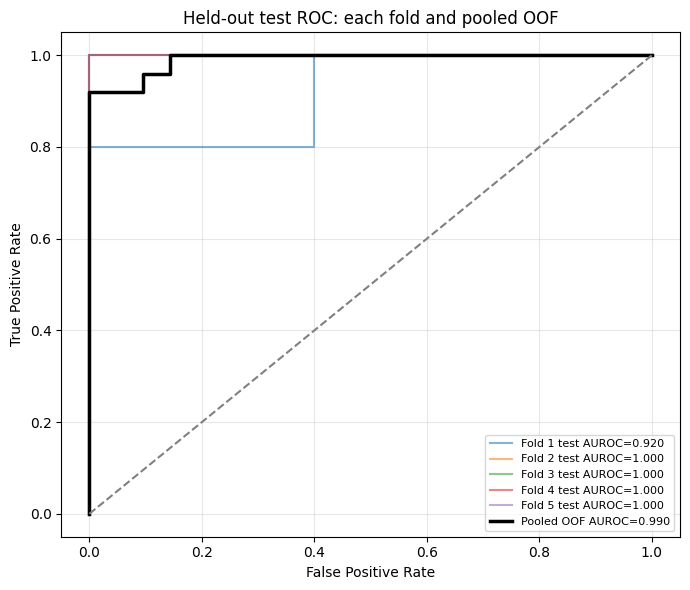

Saved test-only metrics, OOF predictions and ROC in: /content/drive/MyDrive/pd_whisper_results


In [ ]:
# NEW CELL 3 — every fold's TEST metrics + pooled OOF TEST metrics
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_curve

pooled_oof_metrics = {
    "fold": "pooled_oof",
    **test_metrics(y_strict, oof_probability),
}
test_results = pd.concat([
    fold_test_metrics,
    pd.DataFrame([pooled_oof_metrics]),
], ignore_index=True)

print("Only held-out outer-test predictions are used below:")
display(test_results.round(4))
print("Pooled OOF confusion matrix [Healthy=0, PD=1]:")
print(test_results.iloc[-1][["tn", "fp", "fn", "tp"]].to_dict())

oof_predictions = pd.DataFrame({
    "speaker_id": speaker_ids,
    "true_label": y_strict,
    "test_fold": oof_fold,
    "oof_pd_probability": oof_probability,
    "oof_predicted_label_at_0_5": (oof_probability >= 0.5).astype(int),
})
assert oof_predictions.speaker_id.is_unique
assert len(oof_predictions) == len(y_strict)

test_results.to_csv(
    RESULT_DIR / "oof_test_fold_and_pooled_metrics.csv", index=False
)
oof_predictions.to_csv(
    RESULT_DIR / "oof_test_predictions_by_speaker.csv", index=False
)
with (RESULT_DIR / "oof_test_pooled_metrics.json").open(
    "w", encoding="utf-8"
) as f:
    json.dump(pooled_oof_metrics, f, indent=2)

plt.figure(figsize=(7, 6))
for fold, test_idx in enumerate(fold_test_indices, start=1):
    fpr, tpr, _ = roc_curve(
        y_strict[test_idx], oof_probability[test_idx]
    )
    auc_value = fold_test_metrics.loc[
        fold_test_metrics.fold == f"fold_{fold}", "auroc"
    ].iloc[0]
    plt.plot(fpr, tpr, alpha=0.55,
             label=f"Fold {fold} test AUROC={auc_value:.3f}")

fpr, tpr, _ = roc_curve(y_strict, oof_probability)
plt.plot(fpr, tpr, color="black", linewidth=2.5,
         label=f"Pooled OOF AUROC={pooled_oof_metrics['auroc']:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Held-out test ROC: each fold and pooled OOF")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / "oof_test_fold_and_pooled_roc.png", dpi=200)
plt.show()
print("Saved test-only metrics, OOF predictions and ROC in:", RESULT_DIR)


In [ ]:
# CROSS CELL 1 — Google Drive থেকে MDVR-KCL.zip নিয়ে ReadText extract
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
import hashlib
import os
import shutil
from google.colab import drive

drive.mount("/content/drive")
MDVR_ZIP = Path("/content/drive/MyDrive/bilkis/datasets/MDVR-KCL.zip")
MDVR_ROOT = Path("/content/mdvr_kcl_readtext")
RESULT_DIR = Path("/content/drive/MyDrive/pd_whisper_results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

if not MDVR_ZIP.is_file():
    raise FileNotFoundError(
        f"ZIP পাওয়া যায়নি: {MDVR_ZIP}. আগে MDVR-KCL.zip এই Drive folder-এ upload করো।"
    )

expected_zip_sha256 = "b4ec83700557b093820b6cef6efb4c425dfb0dc2d33b4cae6acf28b126bdbf0f"
zip_hasher = hashlib.sha256()
with MDVR_ZIP.open("rb") as f:
    for block in iter(lambda: f.read(1024 * 1024), b""):
        zip_hasher.update(block)
if zip_hasher.hexdigest() != expected_zip_sha256:
    raise ValueError("Drive-এর MDVR-KCL.zip স্থানীয় যাচাই করা ZIP-এর সঙ্গে মেলেনি।")

with ZipFile(MDVR_ZIP) as archive:
    selected = []
    for info in archive.infolist():
        parts = PurePosixPath(info.filename).parts
        if (not info.is_dir() and len(parts) >= 3 and
            parts[-3] == "ReadText" and parts[-2] in {"HC", "PD"} and
            PurePosixPath(info.filename).suffix.lower() == ".wav"):
            if info.filename.startswith("/") or ".." in parts:
                raise ValueError(f"Unsafe ZIP path: {info.filename}")
            selected.append(info)
    if len(selected) != 37:
        raise ValueError(f"ReadText-এ 37 WAV প্রত্যাশিত; পাওয়া গেছে {len(selected)}")

    for info in selected:
        parts = PurePosixPath(info.filename).parts
        destination = MDVR_ROOT / parts[-2] / parts[-1]
        destination.parent.mkdir(parents=True, exist_ok=True)
        if destination.is_file() and destination.stat().st_size == info.file_size:
            continue
        partial = destination.with_suffix(".partial")
        with archive.open(info) as src, partial.open("wb") as dst:
            shutil.copyfileobj(src, dst, length=1024 * 1024)
        if partial.stat().st_size != info.file_size:
            raise IOError(f"Incomplete extraction: {destination}")
        os.replace(partial, destination)

print("Drive ZIP:", MDVR_ZIP)
print("ReadText WAV extracted:", len(list(MDVR_ROOT.rglob("*.wav"))))
print("Only ReadText selected; SpontaneousDialogue excluded.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive ZIP: /content/drive/MyDrive/bilkis/datasets/MDVR-KCL.zip
ReadText WAV extracted: 37
Only ReadText selected; SpontaneousDialogue excluded.


In [ ]:
# CROSS CELL 2 — 37 external speakers, labels ও audio format audit
from pathlib import Path
import hashlib
import re
import wave
import pandas as pd
from IPython.display import display

def audio_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

external_rows = []
for path in sorted(MDVR_ROOT.rglob("*.wav")):
    group = path.parent.name.upper()
    if group not in {"HC", "PD"}:
        raise ValueError(f"Unexpected folder: {path}")
    match = re.fullmatch(r"ID(\d+)_(hc|pd)_\d+_\d+_\d+\.wav",
                         path.name, flags=re.IGNORECASE)
    if match is None or match.group(2).upper() != group:
        raise ValueError(f"Filename/group mismatch: {path}")
    with wave.open(str(path), "rb") as audio:
        sample_rate = audio.getframerate()
        channels = audio.getnchannels()
        duration_s = audio.getnframes() / sample_rate
    if sample_rate != 44100 or channels != 1 or duration_s < 30:
        raise ValueError(f"Unexpected WAV format/duration: {path}")
    external_rows.append({
        "speaker_id": "MDVR_ID" + match.group(1).zfill(2),
        "group": group,
        "label": 1 if group == "PD" else 0,
        "path": str(path),
        "sample_rate": sample_rate,
        "duration_s": duration_s,
        "audio_sha256": audio_sha256(path),
    })

mdvr_manifest = pd.DataFrame(external_rows).sort_values("speaker_id").reset_index(drop=True)
if len(mdvr_manifest) != 37 or mdvr_manifest.speaker_id.nunique() != 37:
    raise ValueError("MDVR ReadText-এ 37 আলাদা speaker প্রত্যাশিত।")
if mdvr_manifest.label.value_counts().to_dict() != {0: 21, 1: 16}:
    raise ValueError("MDVR ReadText label count 21 HC / 16 PD হওয়া উচিত।")
if not mdvr_manifest.audio_sha256.is_unique:
    raise ValueError("External dataset-এ duplicate WAV পাওয়া গেছে।")

mdvr_manifest.to_csv(RESULT_DIR / "mdvr_readtext_manifest.csv", index=False)
print("External test speakers:", len(mdvr_manifest))
display(mdvr_manifest.groupby(["group", "sample_rate"]).size().rename("speakers"))


External test speakers: 37


,,speakers
group,sample_rate,
HC,44100,21
PD,44100,16


In [ ]:
# CROSS CELL 3 — Italian notebook-এর SAME frozen Whisper-large-v3 embedding pipeline
import gc
import hashlib
import numpy as np
import soundfile as sf
import torch
from scipy.signal import resample_poly
from tqdm.auto import tqdm
from transformers import AutoFeatureExtractor, WhisperModel

previous_model_id = globals().get("MODEL_ID")
MODEL_ID = "openai/whisper-large-v3"
if not torch.cuda.is_available():
    raise RuntimeError("Colab Runtime > Change runtime type > GPU নির্বাচন করো।")

if "encoder" not in globals() or "feature_extractor" not in globals():
    feature_extractor = AutoFeatureExtractor.from_pretrained(MODEL_ID)
    whisper_model = WhisperModel.from_pretrained(
        MODEL_ID, dtype=torch.float16, low_cpu_mem_usage=True,
        use_safetensors=True,
    )
    encoder = whisper_model.encoder.to("cuda").eval()
    del whisper_model
    gc.collect()
else:
    if previous_model_id != MODEL_ID:
        raise ValueError("Wrong Whisper model loaded.")
    encoder = encoder.to("cuda").eval()
if feature_extractor.feature_size != 128 or encoder.config.d_model != 1280:
    raise ValueError("Whisper-large-v3 encoder expected (128 mel bins, 1280 hidden).")

MDVR_EMBED_DIR = RESULT_DIR / "mdvr_readtext_whisper_large_v3_embeddings"
MDVR_EMBED_DIR.mkdir(parents=True, exist_ok=True)
WINDOW_SAMPLES = 30 * 16000

def mdvr_load_16k_mono(path):
    audio, sample_rate = sf.read(path, dtype="float32")
    if audio.ndim == 2:
        audio = audio.mean(axis=1)
    if sample_rate != 16000:
        from math import gcd
        factor = gcd(sample_rate, 16000)
        audio = resample_poly(audio, 16000 // factor, sample_rate // factor)
    return audio.astype(np.float32)

def mdvr_thirty_second_windows(audio):
    if len(audio) < WINDOW_SAMPLES:
        raise ValueError("ReadText recording 30 seconds-এর কম।")
    starts = list(range(0, len(audio) - WINDOW_SAMPLES + 1, WINDOW_SAMPLES))
    last_start = len(audio) - WINDOW_SAMPLES
    if starts[-1] != last_start:
        starts.append(last_start)
    return [audio[start:start + WINDOW_SAMPLES] for start in starts]

mdvr_vectors = []
for row in tqdm(mdvr_manifest.itertuples(index=False), total=len(mdvr_manifest)):
    cache_file = MDVR_EMBED_DIR / f"{row.speaker_id}.npz"
    vector = None
    if cache_file.is_file():
        with np.load(cache_file, allow_pickle=False) as cache:
            if (cache["audio_sha256"].item() == row.audio_sha256 and
                cache["model_id"].item() == MODEL_ID and
                cache["vector"].shape == (1280,)):
                vector = cache["vector"].astype(np.float32)
    if vector is None:
        audio = mdvr_load_16k_mono(row.path)
        window_vectors = []
        for chunk in mdvr_thirty_second_windows(audio):
            inputs = feature_extractor(
                chunk, sampling_rate=16000, return_tensors="pt"
            )
            mel = inputs.input_features.to(device="cuda", dtype=torch.float16)
            with torch.inference_mode():
                hidden = encoder(input_features=mel).last_hidden_state
                window_vector = hidden.float().mean(dim=1).squeeze(0).cpu().numpy()
            window_vectors.append(window_vector)
        vector = np.mean(np.stack(window_vectors), axis=0).astype(np.float32)
        np.savez_compressed(
            cache_file, vector=vector,
            audio_sha256=np.array(row.audio_sha256, dtype="U64"),
            model_id=np.array(MODEL_ID, dtype="U32"),
        )
    if vector.shape != (1280,) or not np.isfinite(vector).all():
        raise ValueError(f"Invalid embedding: {row.speaker_id}")
    mdvr_vectors.append(vector)

X_mdvr = np.stack(mdvr_vectors).astype(np.float32)
y_mdvr = mdvr_manifest.label.to_numpy(dtype=int)
print("External X:", X_mdvr.shape, "(37 speakers × 1280 features)")


  0%|          | 0/37 [00:00<?, ?it/s]

External X: (37, 1280) (37 speakers × 1280 features)


In [ ]:
# CROSS CELL 4 — Italian ONLY-তে model fit; MDVR labels tuning-এ ব্যবহার নয়
import joblib
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

if X_strict.shape != (46, 1280) or len(y_strict) != 46:
    raise ValueError("আগে NEW CELL 1 চালিয়ে Italian 46-speaker features তৈরি করো।")
if X_mdvr.shape != (37, 1280):
    raise ValueError("আগে CROSS CELL 3 চালাও।")

# Exact audio duplicate দুই dataset-এর মধ্যে থাকলে external test বন্ধ।
italian_audio_hashes = {audio_sha256(p) for p in manifest_strict.path}
if italian_audio_hashes.intersection(set(mdvr_manifest.audio_sha256)):
    raise ValueError("Italian ও MDVR dataset-এ identical WAV আছে।")

italian_only_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("lr", LogisticRegression(solver="liblinear", max_iter=5000)),
])
ITALIAN_C_GRID = [0.01, 0.1, 1.0, 10.0]  # fixed in the original protocol
italian_inner_cv = StratifiedKFold(
    n_splits=4, shuffle=True, random_state=2026
)
italian_only_search = GridSearchCV(
    italian_only_pipeline, {"lr__C": ITALIAN_C_GRID},
    cv=italian_inner_cv, scoring="roc_auc", refit=True,
    error_score="raise",
)
italian_only_search.fit(X_strict, y_strict)  # ONLY Italian speakers

# Prediction first. MDVR labels are used only in the NEXT evaluation cell.
mdvr_pd_probability = italian_only_search.predict_proba(X_mdvr)[:, 1]
if not np.isfinite(mdvr_pd_probability).all():
    raise ValueError("Non-finite external probabilities.")
model_path = RESULT_DIR / "italian_only_whisper_lr_for_mdvr.joblib"
joblib.dump(italian_only_search.best_estimator_, model_path)
print("Italian-only selected C:", italian_only_search.best_params_["lr__C"])
print("External predictions created for:", len(mdvr_pd_probability), "speakers")
print("Model saved:", model_path)


Italian-only selected C: 0.1
External predictions created for: 37 speakers
Model saved: /content/drive/MyDrive/pd_whisper_results/italian_only_whisper_lr_for_mdvr.joblib


EXTERNAL TEST ONLY (37 never-trained-on MDVR speakers):


,evaluation,training_dataset,test_dataset,train_speakers,test_speakers,test_healthy,test_pd,tn,fp,fn,...,balanced_accuracy,precision_pd,sensitivity_recall_pd,specificity_healthy,negative_predictive_value,f1_pd,f1_macro,mcc,auroc,auprc_average_precision
0,Italian_train_to_MDVR_ReadText_test,Italian_PD_vs_elderly_HC_B1B2,MDVR_KCL_ReadText,46,37,21,16,17,4,9,...,0.6235,0.6364,0.4375,0.8095,0.6538,0.5185,0.621,0.2677,0.6161,0.6531


Confusion matrix [Healthy, PD]:
[[17  4]
 [ 9  7]]


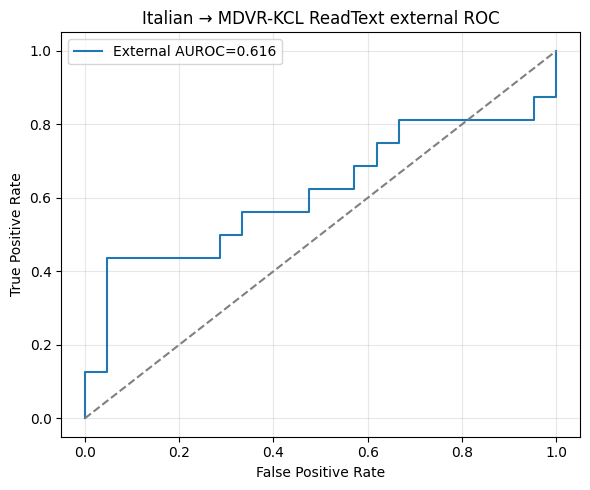

Saved external test results in: /content/drive/MyDrive/pd_whisper_results


In [ ]:
# CROSS CELL 5 — MDVR ReadText external TEST metrics only
import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import confusion_matrix, roc_curve

# test_metrics একই function যা আগের OOF cell-এ ব্যবহৃত হয়েছে।
if "test_metrics" not in globals():
    raise RuntimeError("আগে NEW CELL 2 চালাও, যাতে test_metrics function তৈরি হয়।")
external_metrics = {
    "evaluation": "Italian_train_to_MDVR_ReadText_test",
    "training_dataset": "Italian_PD_vs_elderly_HC_B1B2",
    "test_dataset": "MDVR_KCL_ReadText",
    "train_speakers": 46,
    **test_metrics(y_mdvr, mdvr_pd_probability),
}
print("EXTERNAL TEST ONLY (37 never-trained-on MDVR speakers):")
display(pd.DataFrame([external_metrics]).round(4))
print("Confusion matrix [Healthy, PD]:")
print(confusion_matrix(y_mdvr, mdvr_pd_probability >= 0.5, labels=[0, 1]))

external_predictions = mdvr_manifest[["speaker_id", "group", "label"]].copy()
external_predictions = external_predictions.rename(columns={"label": "true_label"})
external_predictions["pd_probability"] = mdvr_pd_probability
external_predictions["predicted_label_at_0_5"] = (
    mdvr_pd_probability >= 0.5
).astype(int)
external_predictions.to_csv(
    RESULT_DIR / "italian_to_mdvr_external_predictions.csv", index=False
)
pd.DataFrame([external_metrics]).to_csv(
    RESULT_DIR / "italian_to_mdvr_external_metrics.csv", index=False
)
with (RESULT_DIR / "italian_to_mdvr_external_metrics.json").open(
    "w", encoding="utf-8"
) as f:
    json.dump(external_metrics, f, indent=2)

fpr, tpr, _ = roc_curve(y_mdvr, mdvr_pd_probability)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"External AUROC={external_metrics['auroc']:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Italian → MDVR-KCL ReadText external ROC")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / "italian_to_mdvr_external_roc.png", dpi=200)
plt.show()
print("Saved external test results in:", RESULT_DIR)
